# Week 2, Tuesday: Decision Trees & k-Nearest Neighbors
Datasets: **Wine** (3 wine types, 13 chemical features) and **Breast Cancer** (malignant vs benign, 30 features). Both come built into scikit-learn.

## 0. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
sns.set_theme(style='whitegrid')
np.random.seed(42)

## 1. Load and explore both datasets

In [2]:
wine = load_wine(as_frame=True)
cancer = load_breast_cancer(as_frame=True)
for name, d in [('Wine', wine), ('Breast Cancer', cancer)]:
    print(name, '->', d.data.shape, '| classes:', dict(zip(d.target_names, np.bincount(d.target))))
display(wine.data.head())

Wine -> (178, 13) | classes: {np.str_('class_0'): np.int64(59), np.str_('class_1'): np.int64(71), np.str_('class_2'): np.int64(48)}
Breast Cancer -> (569, 30) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
# Do the features live on different scales? (matters a lot for kNN)
summary = wine.data.describe().loc[['min','max']].T
summary['range'] = summary['max'] - summary['min']
summary.sort_values('range', ascending=False).round(2)

,min,max,range
proline,278.00,1680.00,1402.00
magnesium,70.00,162.00,92.00
alcalinity_of_ash,10.60,30.00,19.40
color_intensity,1.28,13.00,11.72
malic_acid,0.74,5.80,5.06
flavanoids,0.34,5.08,4.74
alcohol,11.03,14.83,3.80
proanthocyanins,0.41,3.58,3.17
total_phenols,0.98,3.88,2.90
od280/od315_of_diluted_wines,1.27,4.00,2.73


## 2. Decision Tree: how it works
A tree asks a series of yes/no questions about the features (for example *proline <= 755?*) and each question splits the data into purer groups. It chooses the split that reduces **impurity** the most. **Gini impurity** is 0 when a group contains only one class, and higher when classes are mixed.

In [4]:
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.25, random_state=42, stratify=wine.target)
tree = DecisionTreeClassifier(random_state=42).fit(Xw_tr, yw_tr)
print('Default tree  train:', round(tree.score(Xw_tr, yw_tr), 3), ' test:', round(tree.score(Xw_te, yw_te), 3))
print('Tree depth:', tree.get_depth(), ' leaves:', tree.get_n_leaves())

Default tree  train: 1.0  test: 0.956
Tree depth: 4  leaves: 8


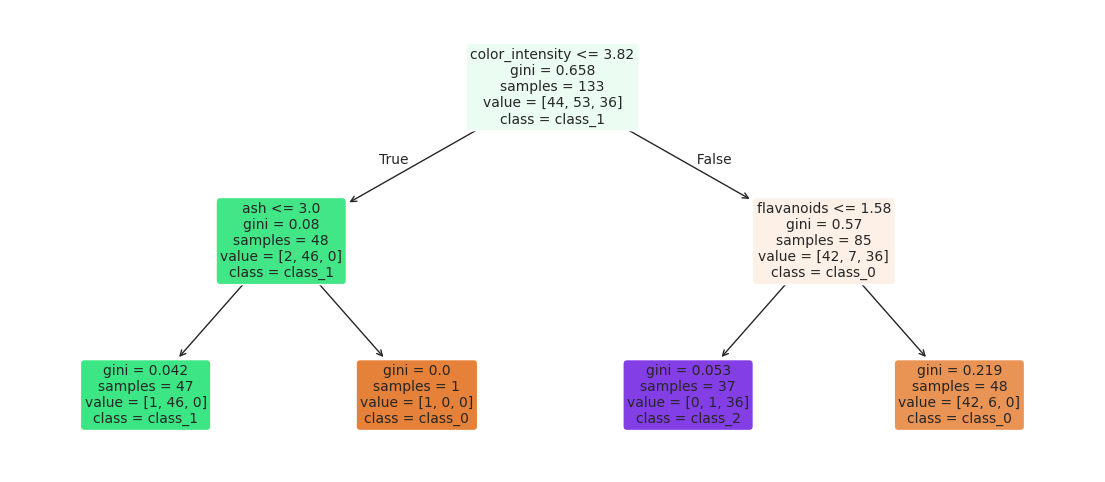

In [5]:
# Plot the top of the tree (first 2 levels) so it is readable
small = DecisionTreeClassifier(max_depth=2, random_state=42).fit(Xw_tr, yw_tr)
plt.figure(figsize=(14, 6))
plot_tree(small, feature_names=wine.feature_names, class_names=list(wine.target_names), filled=True, rounded=True, fontsize=10)
plt.show()

**How to read the tree:** each box shows the question, the **gini** impurity, the number of **samples**, how many are in each class (**value**) and the majority **class**. Follow *True* to the left and *False* to the right.


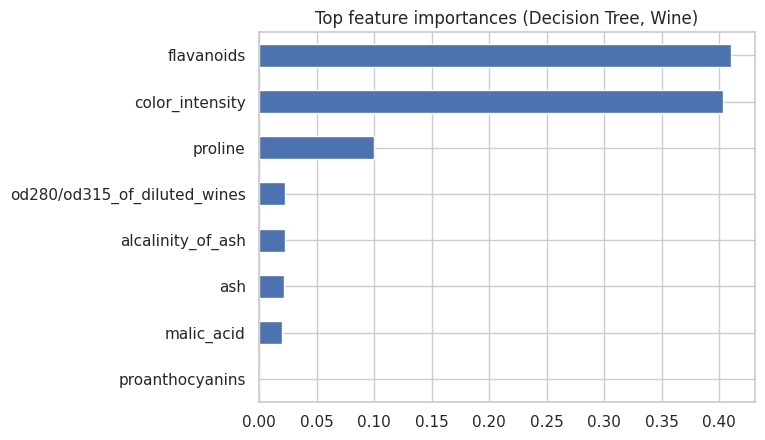

In [6]:
imp = pd.Series(tree.feature_importances_, index=wine.feature_names).sort_values()
imp.tail(8).plot.barh(title='Top feature importances (Decision Tree, Wine)'); plt.show()

## 3. Overfitting in trees: vary `max_depth`
A very deep tree can keep splitting until it memorises the training data. Watch train vs test accuracy as depth grows.

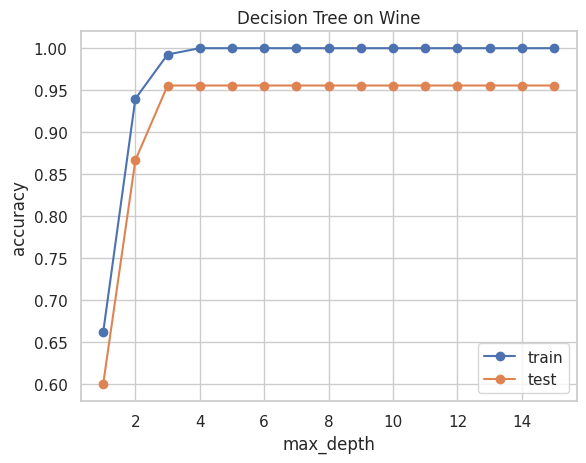

In [7]:
depths = range(1, 16)
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xw_tr, yw_tr)
    tr.append(m.score(Xw_tr, yw_tr)); te.append(m.score(Xw_te, yw_te))
plt.plot(depths, tr, 'o-', label='train'); plt.plot(depths, te, 'o-', label='test')
plt.xlabel('max_depth'); plt.ylabel('accuracy'); plt.title('Decision Tree on Wine'); plt.legend(); plt.show()

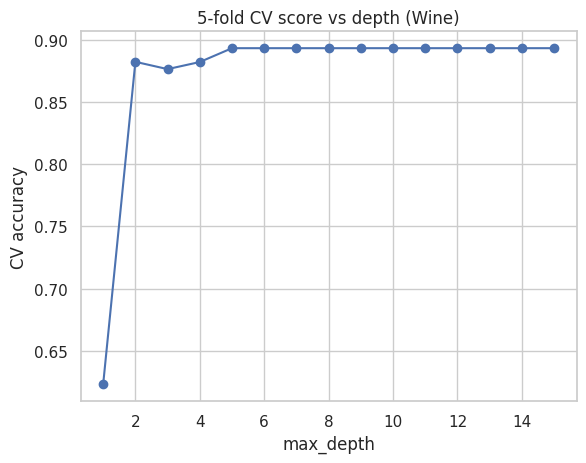

Best depth by CV: 5  score: 0.893


In [8]:
# A single test split is noisy, so confirm with 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_means = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), wine.data, wine.target, cv=cv).mean() for d in depths]
plt.plot(depths, cv_means, 'o-'); plt.xlabel('max_depth'); plt.ylabel('CV accuracy'); plt.title('5-fold CV score vs depth (Wine)'); plt.show()
print('Best depth by CV:', list(depths)[int(np.argmax(cv_means))], ' score:', round(max(cv_means), 3))

## 4. k-Nearest Neighbors: how it works
To classify a new point, kNN finds the **k closest training points** (by distance) and takes a majority vote. There is no real training step: it just stores the data.

Because it uses **distance**, features with big numbers dominate. So scaling should matter a lot.

In [9]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(Xw_tr, yw_tr)
knn_sc = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xw_tr, yw_tr)
print('kNN WITHOUT scaling  test accuracy:', round(knn_raw.score(Xw_te, yw_te), 3))
print('kNN WITH scaling     test accuracy:', round(knn_sc.score(Xw_te, yw_te), 3))

# More reliable: 5-fold CV (the scaler is refit inside each fold by the pipeline)
raw_cv = cross_val_score(KNeighborsClassifier(n_neighbors=5), wine.data, wine.target, cv=cv)
sc_cv = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), wine.data, wine.target, cv=cv)
print(f'CV without scaling: {raw_cv.mean():.3f}   CV with scaling: {sc_cv.mean():.3f}')

kNN WITHOUT scaling  test accuracy: 0.778
kNN WITH scaling     test accuracy: 0.933
CV without scaling: 0.680   CV with scaling: 0.972


## 5. Choosing k: small k overfits, large k underfits

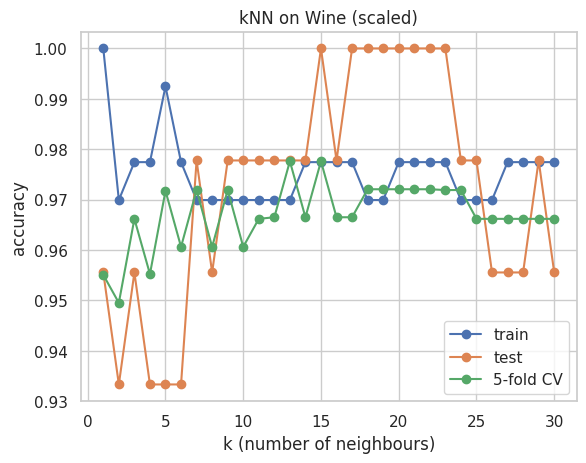

k=1  train: 1.0  test: 0.956
Best k by CV: 13  score: 0.978


In [10]:
ks = range(1, 31)
tr, te, cvm = [], [], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    m.fit(Xw_tr, yw_tr)
    tr.append(m.score(Xw_tr, yw_tr)); te.append(m.score(Xw_te, yw_te))
    cvm.append(cross_val_score(m, wine.data, wine.target, cv=cv).mean())
plt.plot(ks, tr, 'o-', label='train'); plt.plot(ks, te, 'o-', label='test'); plt.plot(ks, cvm, 'o-', label='5-fold CV')
plt.xlabel('k (number of neighbours)'); plt.ylabel('accuracy'); plt.title('kNN on Wine (scaled)'); plt.legend(); plt.show()
print('k=1  train:', round(tr[0], 3), ' test:', round(te[0], 3))
print('Best k by CV:', list(ks)[int(np.argmax(cvm))], ' score:', round(max(cvm), 3))

## 6. Repeat on Breast Cancer: Tree vs kNN (5-fold CV)

,mean accuracy,std
Decision Tree (depth 3),0.924,0.021
Decision Tree (no limit),0.910,0.028
kNN k=5 (no scaling),0.935,0.020
kNN k=5 (scaled),0.963,0.018


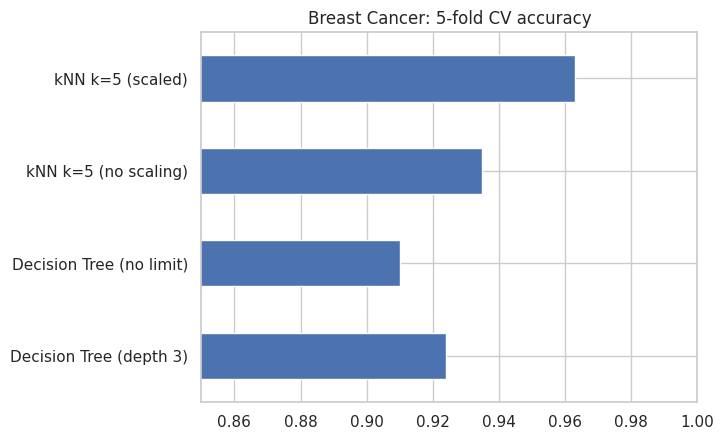

In [11]:
Xc, yc = cancer.data, cancer.target
models = {
    'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Decision Tree (no limit)': DecisionTreeClassifier(random_state=42),
    'kNN k=5 (no scaling)': KNeighborsClassifier(n_neighbors=5),
    'kNN k=5 (scaled)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
res = {n: cross_val_score(m, Xc, yc, cv=cv) for n, m in models.items()}
table = pd.DataFrame({n: [s.mean(), s.std()] for n, s in res.items()}, index=['mean accuracy', 'std']).T.round(3)
display(table)
table['mean accuracy'].plot.barh(xlim=(0.85, 1.0), title='Breast Cancer: 5-fold CV accuracy'); plt.show()